# 04. Target Variable & Class Distribution Analysis

## 4.1 Analisis Variabel Target

Tahap ini bertujuan untuk memahami karakteristik variabel target `status_penanganan` yang digunakan dalam kompetisi Datavidia 11.0 Task 1.

Analisis difokuskan pada distribusi tujuh kelas status penanganan serta perbedaan karakteristik observasi pada setiap kelas.

Beberapa aspek yang dianalisis meliputi:

1. Validitas label target.
2. Distribusi jumlah dan persentase setiap kelas.
3. Tingkat ketidakseimbangan kelas.
4. Perbandingan proporsi kelas.
5. Karakteristik numerik berdasarkan kelas target.
6. Distribusi fitur kategorikal berdasarkan kelas target.
7. Evaluasi diagnostik menggunakan majority class baseline.

Hasil analisis akan digunakan untuk memahami karakteristik setiap kelas dan menentukan strategi pemodelan yang sesuai dengan metrik Macro F1-score.

## 4.2 Target Classification

Permasalahan ini merupakan klasifikasi multikelas dengan tujuh kategori target:

- normal
- konfirmasi_alamat
- tertunda_operasional
- gagal_antar_awal
- retur_pengirim
- rusak_perjalanan
- klaim_hilang

Setiap shipment hanya memiliki satu label target.

In [12]:
from pathlib import Path
import os
import pandas as pd
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
DATA_DIR = Path(r"c:\Users\ASUS\.vscode\arkavidia\data\Task-1-Datavidia-11.0")
OUTPUT_DIR = Path(r"c:\Users\ASUS\.vscode\arkavidia\outputs\04_target_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def read_table(split, table, columns=None):
    path = DATA_DIR / split / f"{table}.csv"

    return pl.read_csv(
        path,
        columns=columns,
        infer_schema_length=20000
    )

def table_columns(split, table):
    return pl.read_csv(DATA_DIR / split / f"{table}.csv", n_rows=0).columns

TARGET_CLASSES = [
    "normal",
    "konfirmasi_alamat",
    "tertunda_operasional",
    "gagal_antar_awal",
    "retur_pengirim",
    "rusak_perjalanan",
    "klaim_hilang"
]

TARGET = "status_penanganan"

In [14]:
train_target = read_table(
    "train",
    "shipments",
    ["shipment_id", TARGET]
)

print("Total training records:", f"{train_target.height:,}")
print("Target variable:", TARGET)
print("Available classes:", TARGET_CLASSES)

Total training records: 1,243,617
Target variable: status_penanganan
Available classes: ['normal', 'konfirmasi_alamat', 'tertunda_operasional', 'gagal_antar_awal', 'retur_pengirim', 'rusak_perjalanan', 'klaim_hilang']


In [15]:
observed_target_classes = set(
    train_target[TARGET]
    .drop_nulls()
    .unique()
    .to_list()
)

missing_target_classes = (
    set(TARGET_CLASSES) - observed_target_classes
)

unexpected_target_classes = (
    observed_target_classes - set(TARGET_CLASSES)
)

target_validation = pd.DataFrame([
    {
        "Validation": "Missing Target Values",
        "Result": train_target[TARGET].null_count(),
        "Status": (
            "Valid"
            if train_target[TARGET].null_count() == 0
            else "Perlu Investigasi"
        )
    },
    {
        "Validation": "Expected Classes",
        "Result": len(missing_target_classes),
        "Status": (
            "Valid"
            if len(missing_target_classes) == 0
            else "Perlu Investigasi"
        )
    },
    {
        "Validation": "Unexpected Classes",
        "Result": len(unexpected_target_classes),
        "Status": (
            "Valid"
            if len(unexpected_target_classes) == 0
            else "Perlu Investigasi"
        )
    }
])

display(target_validation)

print("Missing classes:", missing_target_classes)
print("Unexpected classes:", unexpected_target_classes)

,Validation,Result,Status
0,Missing Target Values,0,Valid
1,Expected Classes,0,Valid
2,Unexpected Classes,0,Valid


Missing classes: set()
Unexpected classes: set()


## 4.3 Target Distribution Analysis

Distribusi target digunakan untuk mengetahui jumlah observasi dan proporsi setiap kategori status penanganan.

Analisis ini penting karena kompetisi menggunakan Macro F1-score, yang memberikan bobot sama kepada seluruh kelas.

Dengan demikian, distribusi target perlu dipahami sebelum menentukan strategi pelatihan model.

Analisis mencakup:

- Jumlah observasi setiap kelas.
- Persentase setiap kelas.
- Urutan kelas berdasarkan frekuensi.
- Rasio kelas terbesar terhadap kelas terkecil.
- Persentase kumulatif distribusi target.

In [16]:
target_counts = (
    train_target
    .group_by(TARGET)
    .len()
    .rename({
        TARGET: "Class",
        "len": "Count"
    })
    .to_pandas()
)

target_distribution_df = pd.DataFrame({
    "Class": TARGET_CLASSES
}).merge(
    target_counts,
    on="Class",
    how="left"
)

target_distribution_df["Count"] = (
    target_distribution_df["Count"].fillna(0).astype(int)
)

target_distribution_df["Percentage"] = (
    target_distribution_df["Count"]
    / target_distribution_df["Count"].sum()
    * 100
)

target_distribution_df = (
    target_distribution_df
    .sort_values("Count", ascending=False)
    .reset_index(drop=True)
)

target_distribution_df["Cumulative Percentage"] = (
    target_distribution_df["Percentage"].cumsum()
)

display(target_distribution_df.round(4))

,Class,Count,Percentage,Cumulative Percentage
0,normal,473531,38.0769,38.0769
1,konfirmasi_alamat,272911,21.9449,60.0219
2,tertunda_operasional,185496,14.9158,74.9377
3,gagal_antar_awal,124341,9.9983,84.9360
4,retur_pengirim,87740,7.0552,91.9913
5,rusak_perjalanan,61942,4.9808,96.9721
6,klaim_hilang,37656,3.0279,100.0000


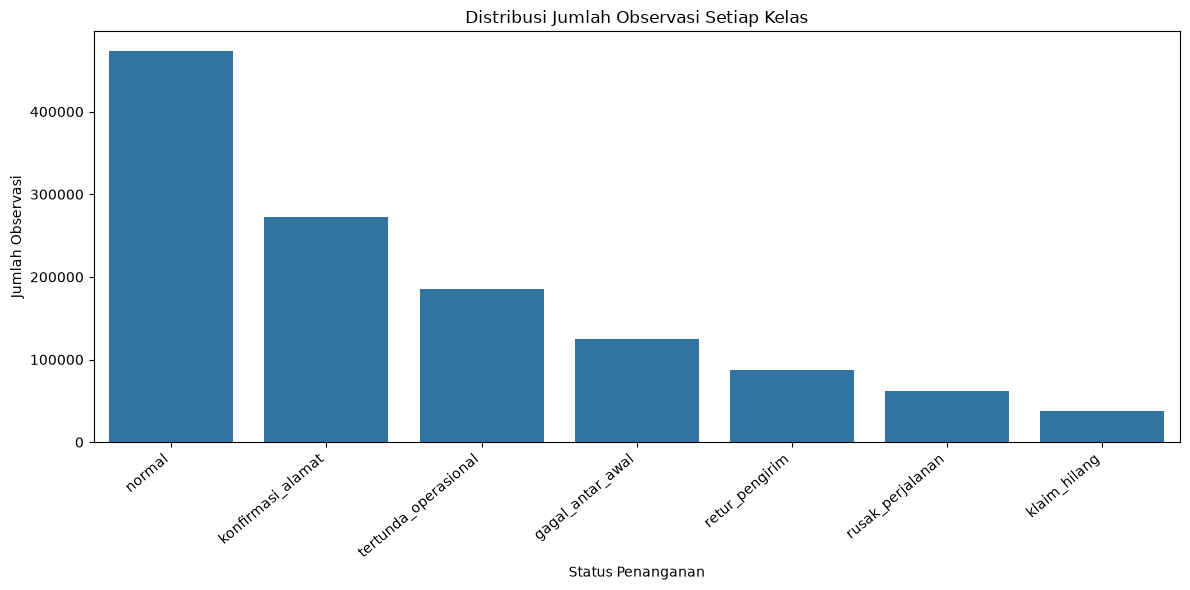

In [17]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=target_distribution_df,
    x="Class",
    y="Count"
)

plt.title("Distribusi Jumlah Observasi Setiap Kelas")
plt.xlabel("Status Penanganan")
plt.ylabel("Jumlah Observasi")
plt.xticks(rotation=40, ha="right")

plt.tight_layout()
plt.show()

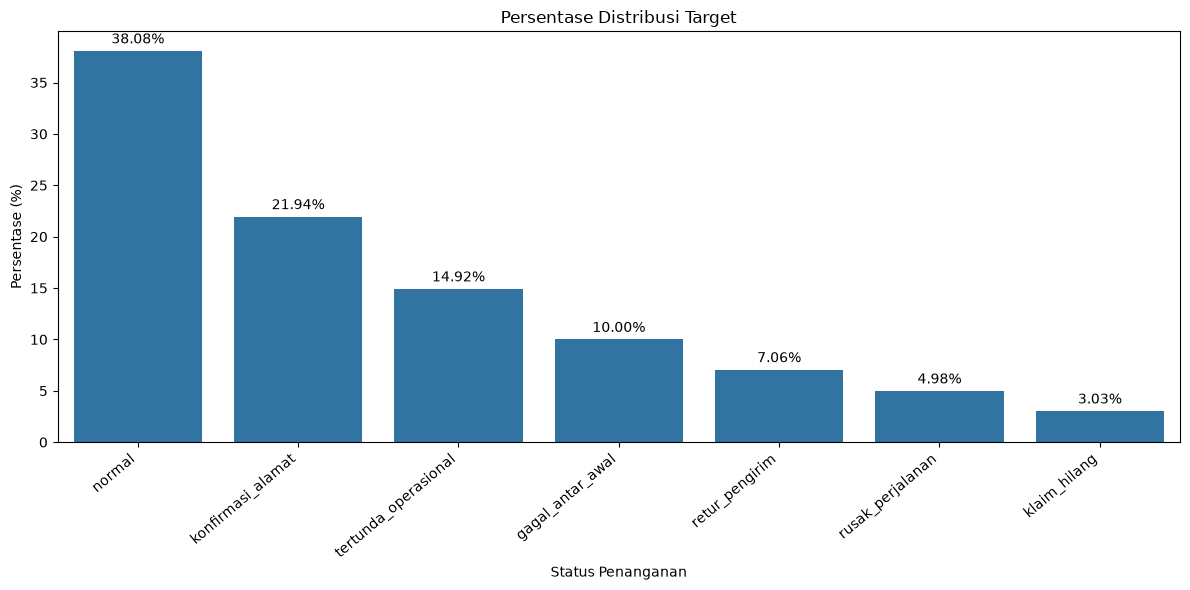

In [18]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=target_distribution_df,
    x="Class",
    y="Percentage"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3
    )

plt.title("Persentase Distribusi Target")
plt.xlabel("Status Penanganan")
plt.ylabel("Persentase (%)")
plt.xticks(rotation=40, ha="right")

plt.tight_layout()
plt.show()

In [19]:
majority_class = target_distribution_df.iloc[0]
minority_class = target_distribution_df.iloc[-1]

imbalance_ratio = (
    majority_class["Count"] /
    minority_class["Count"]
    if minority_class["Count"] > 0 else np.nan
)

class_imbalance_summary = pd.DataFrame([
    {
        "Metric": "Total Observations",
        "Value": train_target.height
    },
    {
        "Metric": "Number of Classes",
        "Value": len(TARGET_CLASSES)
    },
    {
        "Metric": "Majority Class",
        "Value": majority_class["Class"]
    },
    {
        "Metric": "Majority Count",
        "Value": majority_class["Count"]
    },
    {
        "Metric": "Majority Percentage",
        "Value": majority_class["Percentage"]
    },
    {
        "Metric": "Minority Class",
        "Value": minority_class["Class"]
    },
    {
        "Metric": "Minority Count",
        "Value": minority_class["Count"]
    },
    {
        "Metric": "Minority Percentage",
        "Value": minority_class["Percentage"]
    },
    {
        "Metric": "Imbalance Ratio",
        "Value": round(imbalance_ratio, 4)
    }
])

display(class_imbalance_summary)

,Metric,Value
0,Total Observations,1243617
1,Number of Classes,7
2,Majority Class,normal
3,Majority Count,473531
4,Majority Percentage,38.076916
5,Minority Class,klaim_hilang
6,Minority Count,37656
7,Minority Percentage,3.027942
8,Imbalance Ratio,12.5752


## 4.4 Class-Level Feature Profiling

Setelah memahami distribusi target, analisis dilanjutkan dengan mempelajari karakteristik setiap kelas.

Tujuannya adalah mengidentifikasi perbedaan karakteristik shipment yang berkaitan dengan masing-masing status penanganan.

Analisis dibagi menjadi dua kelompok:

1. Numerical Feature Profiling

   Membandingkan nilai rata-rata, median, dan standar deviasi fitur numerik pada setiap kelas.

2. Categorical Feature Profiling

   Membandingkan distribusi kategori fitur kategorikal terhadap masing-masing kelas target.

Fitur yang dianalisis meliputi karakteristik nilai barang, jarak pengiriman, jumlah catatan, waktu pengiriman, serta informasi pengiriman lainnya.

Hasil analisis digunakan untuk mengidentifikasi potensi fitur prediktif dan hubungan antarvariabel.

In [ ]:
NUMERIC_CANDIDATES = [
    "declared_value",
    "distance_km",
    "jumlah_catatan",
    "ship_month",
    "ship_hour",
    "ship_dow",
    "weight_kg",
    "volume_l",
    "berat_volumetrik",
    "qty_items",
    "flag_alamat_baru",
    "is_cod",
    "coupon_count",
    "gift_wrap",
    "insurance_opt"
]

CATEGORICAL_CANDIDATES = [
    "goods_category",
    "channel",
    "pickup_type",
    "dest_region",
    "kota_asal",
    "kota_tujuan",
    "is_cod",
    "flag_alamat_baru",
    "gift_wrap",
    "insurance_opt"
]

# Cek kolom dari header CSV saja (hemat RAM)
shipment_columns = table_columns("train", "shipments")

available_numeric_features = [
    column
    for column in NUMERIC_CANDIDATES
    if column in shipment_columns
]

print("Numeric features:", available_numeric_features)

# Baca hanya kolom yang dibutuhkan agar hemat RAM
needed_columns = list(dict.fromkeys(
    [TARGET]
    + available_numeric_features
    + [c for c in CATEGORICAL_CANDIDATES if c in shipment_columns]
))

shipment_numeric = read_table(
    "train",
    "shipments",
    needed_columns
)

numeric_expressions = []

for feature in available_numeric_features:

    col = pl.col(feature).cast(pl.Float64, strict=False)

    numeric_expressions.extend([
        col.mean().alias(f"{feature}_mean"),
        col.median().alias(f"{feature}_median"),
        col.std().alias(f"{feature}_std")
    ])

class_numeric_profile_df = (
    shipment_numeric
    .group_by(TARGET)
    .agg(numeric_expressions)
    .sort(TARGET)
    .to_pandas()
)

display(class_numeric_profile_df)

Numeric features: ['declared_value', 'distance_km', 'jumlah_catatan', 'ship_month', 'ship_hour', 'ship_dow', 'weight_kg', 'volume_l', 'berat_volumetrik', 'qty_items', 'flag_alamat_baru', 'is_cod', 'coupon_count', 'gift_wrap', 'insurance_opt']


,status_penanganan,declared_value_mean,declared_value_median,declared_value_std,distance_km_mean,distance_km_median,distance_km_std,jumlah_catatan_mean,jumlah_catatan_median,jumlah_catatan_std,...,is_cod_std,coupon_count_mean,coupon_count_median,coupon_count_std,gift_wrap_mean,gift_wrap_median,gift_wrap_std,insurance_opt_mean,insurance_opt_median,insurance_opt_std
0,gagal_antar_awal,131354.854794,75000.0,183386.009292,856.234406,838.40,393.519537,0.491511,0.0,0.636994,...,0.243636,0.311378,0.0,0.518217,0.089407,0.0,0.285332,0.545251,1.0,0.497950
1,klaim_hilang,411054.971319,257000.0,512912.250140,872.038135,855.40,398.865809,0.381347,0.0,0.599824,...,0.239916,0.312566,0.0,0.522171,0.090530,0.0,0.286943,0.542596,1.0,0.498189
2,konfirmasi_alamat,134808.948705,75000.0,194584.813594,893.295819,885.70,401.263045,0.768536,1.0,0.650263,...,0.244484,0.311842,0.0,0.520412,0.089648,0.0,0.285678,0.547182,1.0,0.497770
3,normal,116181.770570,66000.0,165966.579816,842.300944,824.10,404.720684,0.357349,0.0,0.584688,...,0.244109,0.312343,0.0,0.520963,0.089924,0.0,0.286074,0.544287,1.0,0.498035
4,retur_pengirim,122482.653294,72000.0,163162.949827,889.370288,879.55,397.620929,0.462765,0.0,0.625057,...,0.284089,0.313403,0.0,0.519621,0.090620,0.0,0.287070,0.545521,1.0,0.497926
5,rusak_perjalanan,131953.036712,75000.0,180582.381798,1174.436965,1201.60,337.187556,0.368441,0.0,0.589093,...,0.242257,0.316490,0.0,0.523168,0.089713,0.0,0.285772,0.551435,1.0,0.497351
6,tertunda_operasional,132438.607841,75000.0,194399.665333,959.308585,965.55,400.567626,0.407459,0.0,0.608694,...,0.244295,0.313209,0.0,0.521398,0.088466,0.0,0.283971,0.545510,1.0,0.497926


In [21]:
numeric_mean_columns = [
    f"{feature}_mean"
    for feature in available_numeric_features
]

numeric_mean_profile = class_numeric_profile_df[
    ["status_penanganan"] + numeric_mean_columns
].set_index("status_penanganan")

numeric_mean_profile.columns = [
    column.replace("_mean", "")
    for column in numeric_mean_profile.columns
]

display(numeric_mean_profile.round(3))  

,declared_value,distance_km,jumlah_catatan,ship_month,ship_hour,ship_dow,weight_kg,volume_l,berat_volumetrik,qty_items,flag_alamat_baru,is_cod,coupon_count,gift_wrap,insurance_opt
status_penanganan,,,,,,,,,,,,,,,
gagal_antar_awal,131354.855,856.234,0.492,6.707,12.505,3.009,4.128,9.498,8.667,1.907,0.143,0.063,0.311,0.089,0.545
klaim_hilang,411054.971,872.038,0.381,6.685,12.470,3.023,4.115,9.476,8.653,1.892,0.109,0.061,0.313,0.091,0.543
konfirmasi_alamat,134808.949,893.296,0.769,6.743,12.497,2.999,4.139,9.523,8.684,1.897,0.198,0.064,0.312,0.090,0.547
normal,116181.771,842.301,0.357,6.587,12.493,3.002,4.142,9.520,8.702,1.901,0.100,0.064,0.312,0.090,0.544
retur_pengirim,122482.653,889.370,0.463,6.741,12.493,3.001,4.155,9.561,8.725,1.900,0.135,0.089,0.313,0.091,0.546
rusak_perjalanan,131953.037,1174.437,0.368,6.705,12.480,3.008,4.114,9.463,8.634,1.900,0.108,0.063,0.316,0.090,0.551
tertunda_operasional,132438.608,959.309,0.407,7.395,12.502,2.999,4.152,9.529,8.717,1.907,0.114,0.064,0.313,0.088,0.546


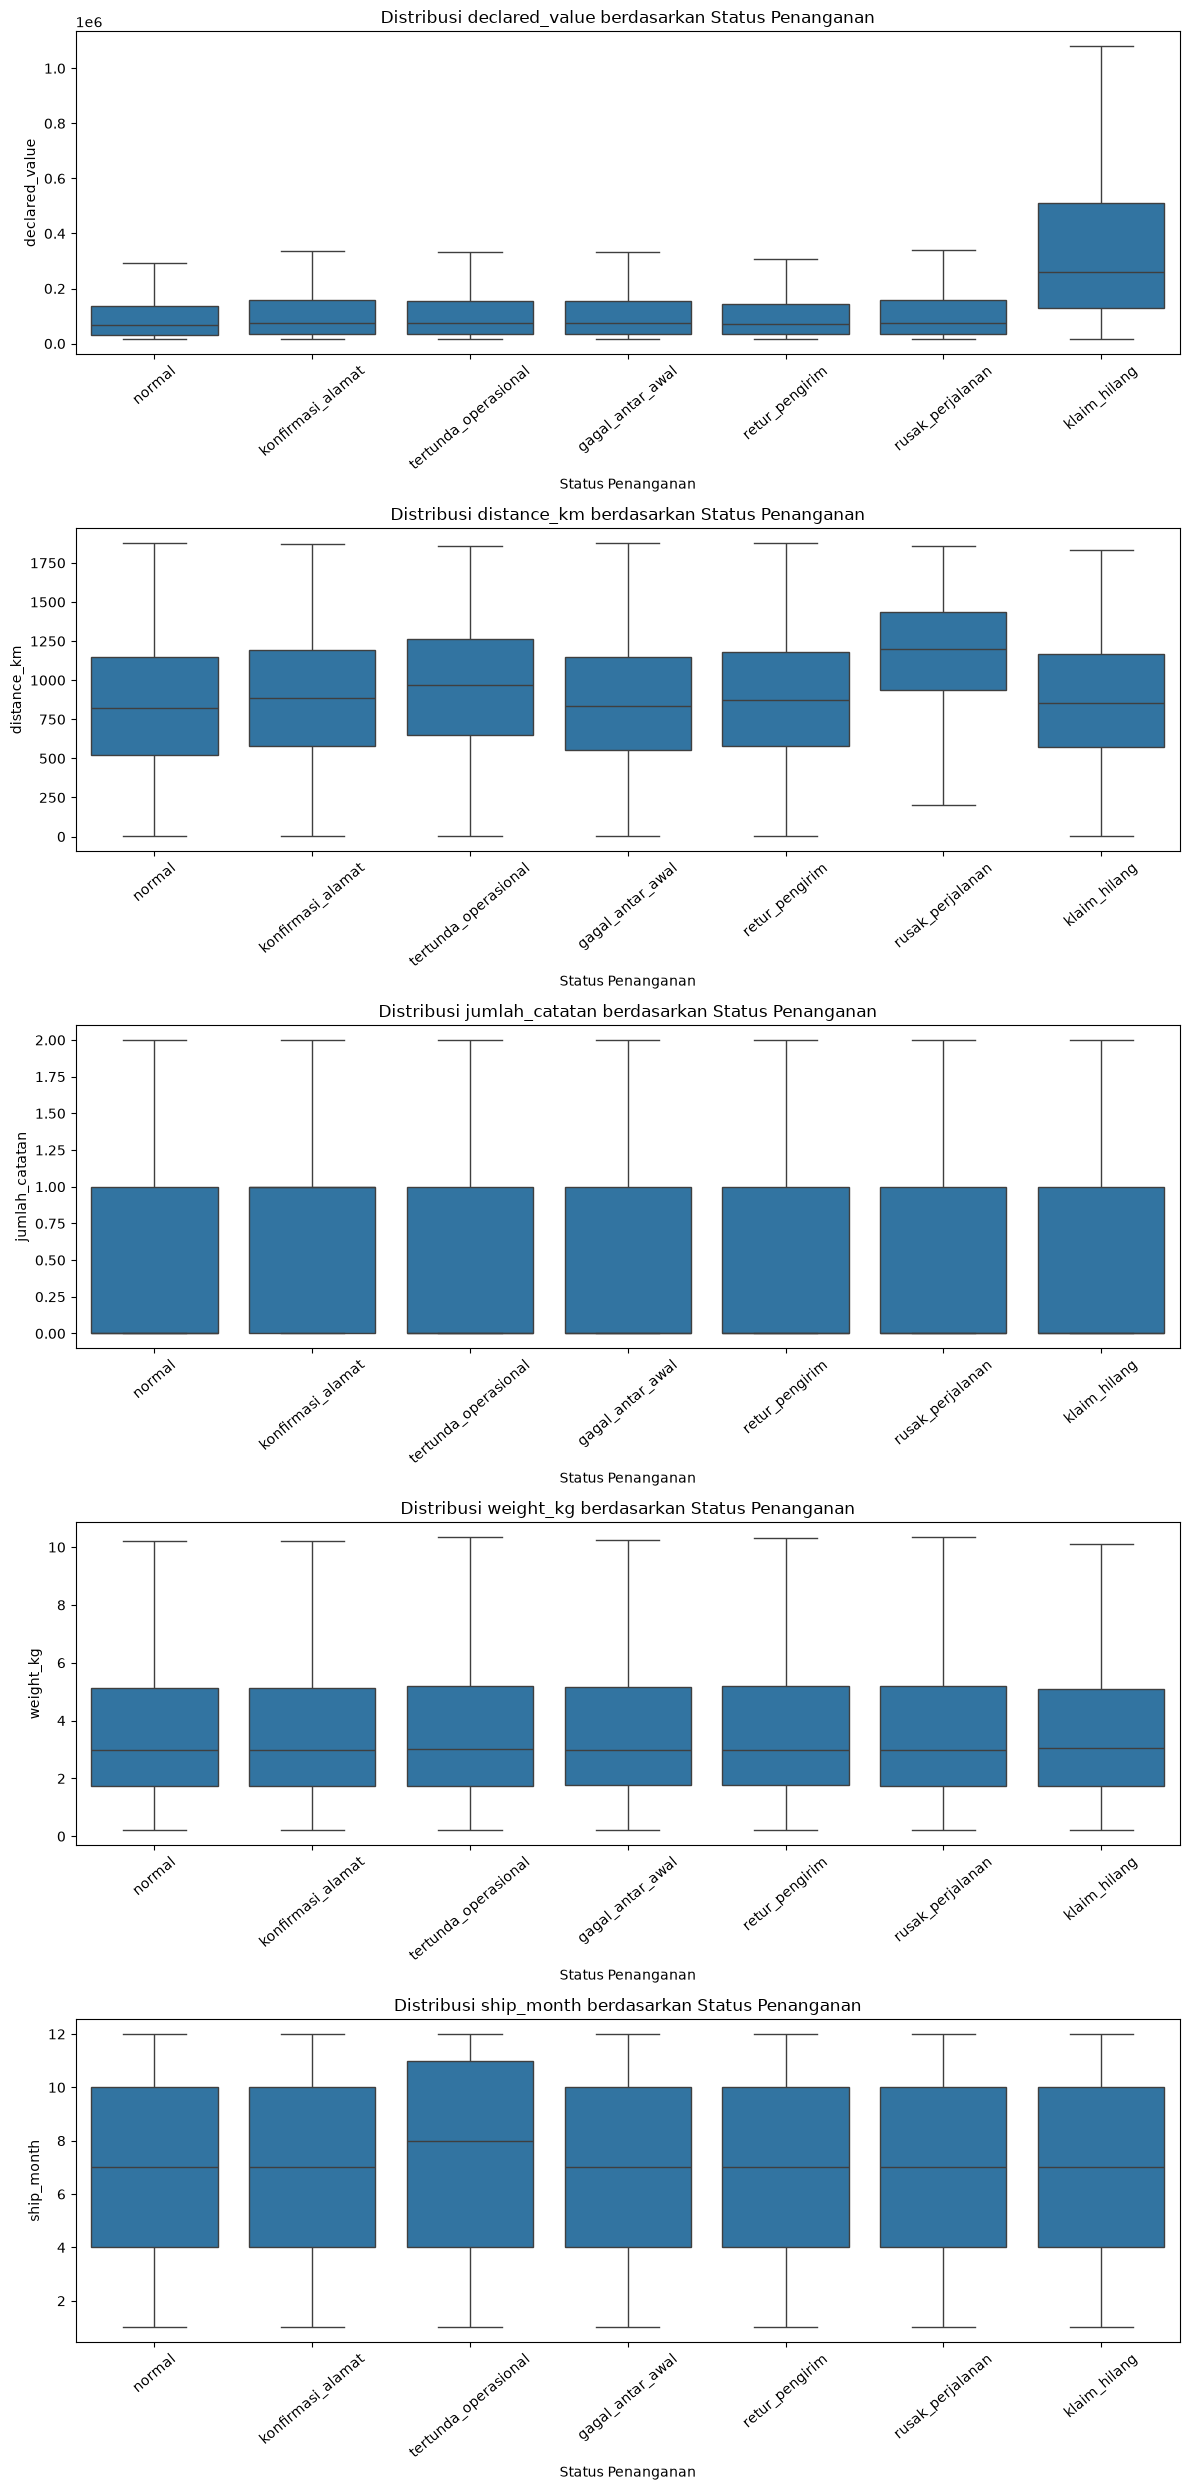

In [27]:
selected_features = [
    feature
    for feature in [
        "declared_value",
        "distance_km",
        "jumlah_catatan",
        "weight_kg",
        "ship_month"
    ]
    if feature in available_numeric_features
]

if not selected_features:
    print("Tidak ada fitur numerik yang tersedia untuk diplot.")
else:
    # Sampel agar tidak mengonversi 1,2 juta baris ke pandas
    plot_df = (
        shipment_numeric
        .select([TARGET] + selected_features)
        .sample(n=min(200_000, shipment_numeric.height), seed=42)
        .to_pandas()
    )

    fig, axes = plt.subplots(
        len(selected_features),
        1,
        figsize=(12, 5 * len(selected_features))
    )

    if len(selected_features) == 1:
        axes = [axes]

    for ax, feature in zip(axes, selected_features):

        sns.boxplot(
            data=plot_df,
            x=TARGET,
            y=feature,
            order=TARGET_CLASSES,
            showfliers=False,
            ax=ax
        )

        ax.set_title(f"Distribusi {feature} berdasarkan Status Penanganan")
        ax.set_xlabel("Status Penanganan")
        ax.set_ylabel(feature)
        ax.tick_params(
            axis="x",
            rotation=40
        )

    plt.tight_layout()
    plt.show()

plot_data = (
    shipment_numeric
    .select([TARGET] + selected_features)
    .sample(
        n=min(150000, shipment_numeric.height),
        seed=42
    )
    .to_pandas()
)

## 4.5 Categorical Feature Profiling

Analisis fitur kategorikal dilakukan untuk mengidentifikasi perbedaan distribusi kategori pada masing-masing status penanganan.

Fitur yang diamati meliputi:

- Goods category.
- Channel pengiriman.
- Pickup type.
- COD status.
- Kategori wilayah tujuan.

Analisis dilakukan dengan menghitung frekuensi dan proporsi masing-masing kategori berdasarkan status penanganan.

Tujuannya adalah mengetahui apakah terdapat kategori tertentu yang memiliki kecenderungan lebih tinggi terhadap status pengiriman tertentu.

Hasil analisis dapat digunakan sebagai pertimbangan dalam pemilihan fitur dan strategi encoding pada tahap modeling.

In [23]:
CATEGORICAL_CANDIDATES = [
    "goods_category",
    "channel",
    "pickup_type",
    "dest_region",
    "kota_asal",
    "kota_tujuan",
    "is_cod",
    "flag_alamat_baru",
    "gift_wrap",
    "insurance_opt"
]

available_categorical_features = [
    column
    for column in CATEGORICAL_CANDIDATES
    if column in shipment_numeric.columns
]

categorical_profile_records = []

for feature in available_categorical_features:

    category_summary = (
        shipment_numeric
        .group_by([TARGET, feature])
        .len()
        .sort([TARGET, "len"], descending=[False, True])
    )

    category_summary = category_summary.with_columns(
        (
            pl.col("len")
            / pl.col("len").sum().over(TARGET)
            * 100
        ).alias("Percentage")
    )

    category_pdf = category_summary.to_pandas()

    category_pdf["Feature"] = feature

    categorical_profile_records.append(category_pdf)

categorical_class_profile_df = pd.concat(
    categorical_profile_records,
    ignore_index=True
) if categorical_profile_records else pd.DataFrame()

display(categorical_class_profile_df)

,status_penanganan,goods_category,len,Percentage,Feature,channel,pickup_type,dest_region,kota_asal,kota_tujuan,is_cod,flag_alamat_baru,gift_wrap,insurance_opt
0,gagal_antar_awal,dokumen,20820,16.744276,goods_category,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,gagal_antar_awal,elektronik,20813,16.738646,goods_category,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,gagal_antar_awal,perabot,20733,16.674307,goods_category,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,gagal_antar_awal,kesehatan,20706,16.652592,goods_category,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,gagal_antar_awal,makanan,20675,16.627661,goods_category,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
807,retur_pengirim,NaN,39876,45.447914,insurance_opt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
808,rusak_perjalanan,NaN,34157,55.143521,insurance_opt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
809,rusak_perjalanan,NaN,27785,44.856479,insurance_opt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
810,tertunda_operasional,NaN,101190,54.551042,insurance_opt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0


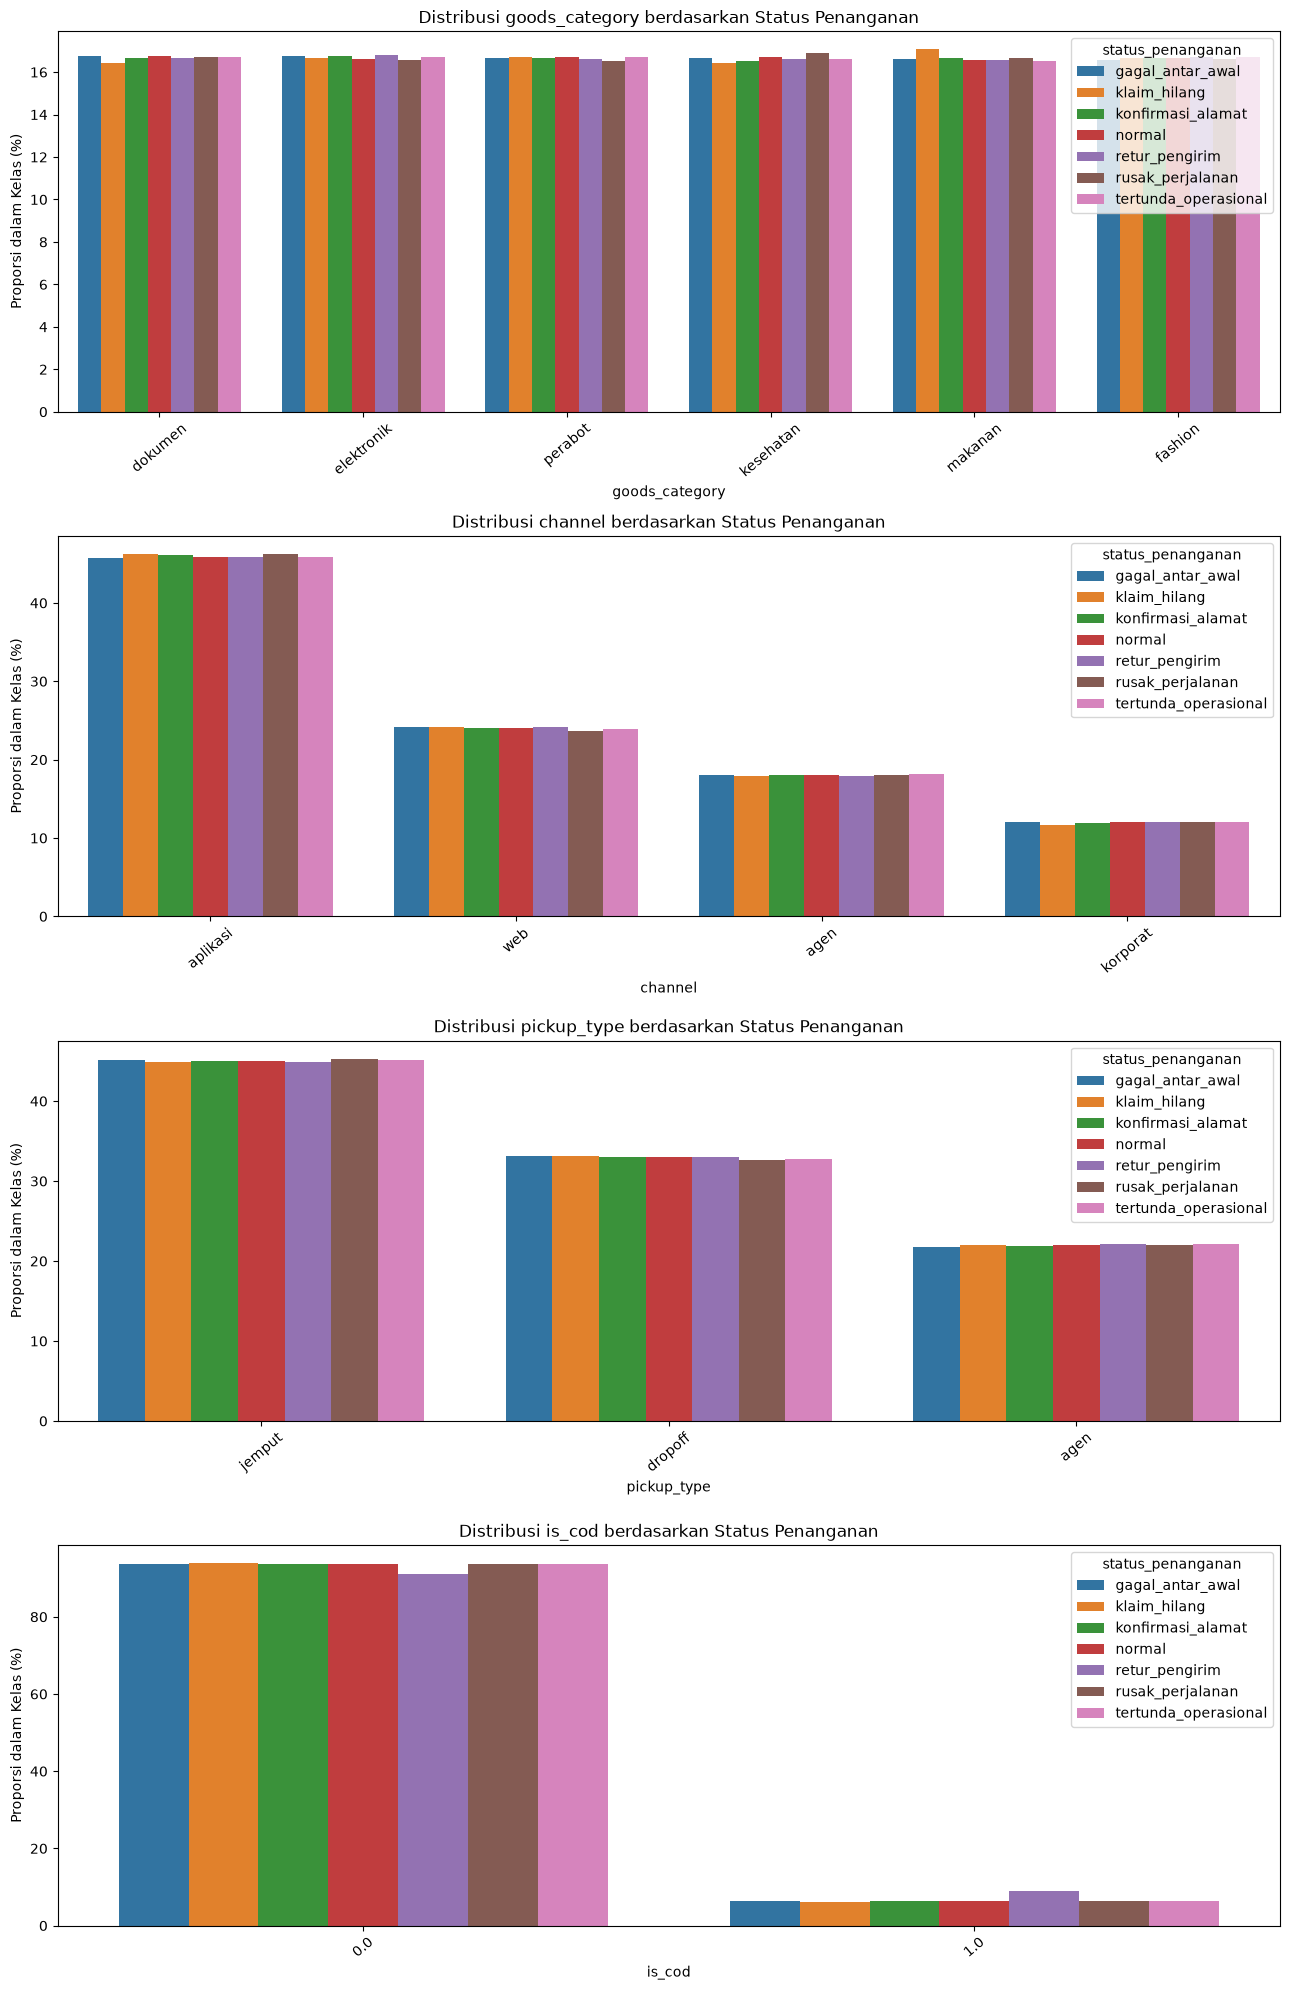

In [24]:
plot_categories = [
    feature
    for feature in [
        "goods_category",
        "channel",
        "pickup_type",
        "is_cod"
    ]
    if feature in available_categorical_features
]

if not plot_categories:
    print("Tidak ada fitur kategorikal yang tersedia untuk diplot.")
else:
    fig, axes = plt.subplots(
        len(plot_categories),
        1,
        figsize=(13, 5 * len(plot_categories))
    )

    if len(plot_categories) == 1:
        axes = [axes]

    for ax, feature in zip(axes, plot_categories):

        data = categorical_class_profile_df[
            categorical_class_profile_df["Feature"] == feature
        ]

        sns.barplot(
            data=data,
            x=feature,
            y="Percentage",
            hue=TARGET,
            ax=ax
        )

        ax.set_title(
            f"Distribusi {feature} berdasarkan Status Penanganan"
        )

        ax.set_xlabel(feature)
        ax.set_ylabel("Proporsi dalam Kelas (%)")
        ax.tick_params(
            axis="x",
            rotation=40
        )

    plt.tight_layout()
    plt.show()

## 4.6 Majority Class Baseline

Majority class baseline merupakan pendekatan sederhana yang selalu memprediksi kelas dengan jumlah observasi terbanyak.

Analisis ini digunakan untuk memahami keterbatasan pendekatan yang hanya mengandalkan dominasi kelas mayoritas.

Evaluasi dilakukan menggunakan:

- Accuracy.
- Macro Precision.
- Macro Recall.
- Macro F1-score.

Hasil ini hanya digunakan sebagai baseline diagnostik untuk memahami distribusi target dan ketimpangan performa antar kelas.

Nilainya bukan estimasi generalisasi model karena prediksi diagnostik dibuat menggunakan distribusi keseluruhan training dataset.

In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score
)

y_true = train_target[TARGET].to_list()

majority_label = majority_class["Class"]

y_majority_pred = [
    majority_label
] * len(y_true)

majority_accuracy = accuracy_score(
    y_true,
    y_majority_pred
)

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_true,
        y_majority_pred,
        labels=TARGET_CLASSES,
        zero_division=0
    )
)

majority_f1 = f1_score(
    y_true,
    y_majority_pred,
    labels=TARGET_CLASSES,
    average="macro",
    zero_division=0
)

majority_baseline_df = pd.DataFrame({
    "Class": TARGET_CLASSES,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "Support": support
})

display(majority_baseline_df)

print("Majority Class:", majority_label)
print("Accuracy:", round(majority_accuracy, 4))
print("Macro F1:", round(majority_f1, 4))

,Class,Precision,Recall,F1 Score,Support
0,normal,0.380769,1.0,0.551532,473531
1,konfirmasi_alamat,0.000000,0.0,0.000000,272911
2,tertunda_operasional,0.000000,0.0,0.000000,185496
3,gagal_antar_awal,0.000000,0.0,0.000000,124341
4,retur_pengirim,0.000000,0.0,0.000000,87740
5,rusak_perjalanan,0.000000,0.0,0.000000,61942
6,klaim_hilang,0.000000,0.0,0.000000,37656


Majority Class: normal
Accuracy: 0.3808
Macro F1: 0.0788


## 4.7 Target Analysis Findings

Berdasarkan hasil analisis distribusi target dan karakteristik setiap kelas, dilakukan evaluasi awal terhadap permasalahan klasifikasi.

Aspek yang menjadi perhatian utama meliputi:

1. Distribusi observasi pada tujuh kelas.
2. Tingkat ketidakseimbangan antara kelas mayoritas dan minoritas.
3. Perbedaan karakteristik numerik antar kelas.
4. Distribusi fitur kategorikal berdasarkan target.
5. Keterbatasan model yang hanya memprediksi kelas mayoritas.

Karakteristik tersebut akan menjadi dasar dalam menentukan strategi feature engineering dan optimasi model.

Mengingat kompetisi menggunakan Macro F1-score, pengembangan model perlu memperhatikan performa seluruh kelas, bukan hanya kelas dengan jumlah observasi terbesar.

Kesimpulan akhir akan diperkuat melalui validasi silang dan evaluasi performa model pada tahap eksperimen.

In [26]:
section04_outputs = {
    "target_distribution.csv": target_distribution_df,
    "target_validation.csv": target_validation,
    "class_imbalance_summary.csv": class_imbalance_summary,
    "class_numeric_profile.csv": class_numeric_profile_df,
    "class_categorical_profile.csv": categorical_class_profile_df,
    "majority_baseline.csv": majority_baseline_df
}

for filename, dataframe in section04_outputs.items():

    dataframe.to_csv(
        OUTPUT_DIR / filename,
        index=False
    )

print("Section 04 completed.")
print("Total output files:", len(section04_outputs))
print("Output directory:", OUTPUT_DIR.resolve())

Section 04 completed.
Total output files: 6
Output directory: C:\Users\ASUS\.vscode\arkavidia\outputs\04_target_analysis
